# Crowding with a vision-language model

Qwen3-VL-2B-Instruct names a letter that sits alone or between two other letters. The
displays are drawn by `stimuli.py` in this folder (letter size and spacing after Bouma, 1970):

- target at **0°** (image centre) or **10°** (right of centre)
- flankers at **1, 2, 4, 8 or 16 letter slots** (0.29 to 4.7°), or none
- 25 letters × 4 = **100 trials per condition**, 1,200 in all

Results go to `../data/model_results.csv`, one row per trial. `analysis.ipynb` makes the numbers
and figures from that file.

Needs a GPU: in Colab, Runtime > Change runtime type > T4 GPU. The run takes a few minutes.

## Setup

In [1]:
import os
import sys

inColab = "google.colab" in sys.modules

if inColab:
  from google.colab import drive
  drive.mount("/content/drive")
  os.chdir("/content/drive/MyDrive/Projects/vlm-psychophysics/chapters/crowding/code")
  os.system("pip install -q -U transformers")

sys.path.insert(0, os.getcwd())
print("running in Colab:", inColab)
print("folder:", os.getcwd())

Mounted at /content/drive
running in Colab: True
folder: /content/drive/MyDrive/Projects/vlm-psychophysics/chapters/crowding/code


In [2]:
import time
import torch
import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
from transformers       import AutoModelForImageTextToText, AutoProcessor
from transformers.utils import logging

import stimuli

logging.disable_progress_bar()
logging.set_verbosity_error()

if torch.cuda.is_available():
  device = "cuda"
  dtype  = torch.float16
else:
  device = "cpu"
  dtype  = torch.float32

print("device:", device)

device: cuda


In [3]:
modelName = "Qwen/Qwen3-VL-2B-Instruct"

model = AutoModelForImageTextToText.from_pretrained(modelName, dtype=dtype)
model = model.to(device)
model = model.eval()
proc  = AutoProcessor.from_pretrained(modelName)


def makeInputs(img, question):
  messages = [
    {"role": "user",
     "content": [
       {"type": "image", "image": img},
       {"type": "text",  "text":  question},
     ]}
  ]
  inputs = proc.apply_chat_template(messages,
                                    tokenize=True,
                                    add_generation_prompt=True,
                                    return_dict=True,
                                    return_tensors="pt")
  inputs = inputs.to(device)
  inputs["pixel_values"] = inputs["pixel_values"].to(dtype)
  return inputs


def nextWordScores(img, question):
  # one forward pass: a score for every word the model could say first
  inputs = makeInputs(img, question)
  with torch.no_grad():
    output = model(**inputs, logits_to_keep=1)
  return output.logits[0, -1].float().cpu()

print("model loaded")

model loaded


## The question and the scoring

The same question for every display:

> There is either one letter or a row of three letters. If there are three, name the middle
> one. If there is one, name it. Answer with a single lowercase letter.

The answer is the most likely of the 25 letters (a-z without x), so guessing gives 1/25.

In [4]:
question = ("There is either one letter or a row of three letters. If there are three, name the middle one. "
            "If there is one, name it. Answer with a single lowercase letter.")
letters  = stimuli.LETTERS

# token IDs of " a", " b", ... (with the leading space); each must be a single token
letterIds = []
for L in letters:
  ids = proc.tokenizer.encode(" " + L, add_special_tokens=False)
  assert len(ids) == 1, L
  letterIds.append(ids[0])


def letterProbs(img):
  scores = nextWordScores(img, question)
  return torch.softmax(scores[letterIds], dim=0).numpy()

## A check before the run

Two easy displays (flankers 8 slots away). The model should name "k", and it should see the
image at its real size (1024 × 128, no resizing).

 0 deg: model sees 1024 x 128 px; answer k (p = 1.00)
10 deg: model sees 1024 x 128 px; answer k (p = 1.00)


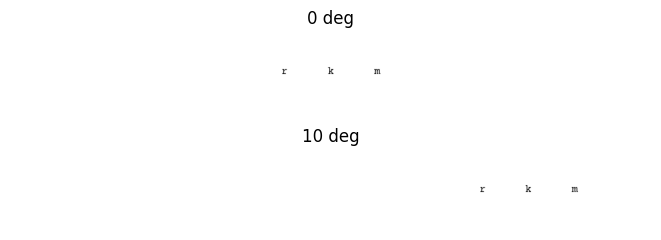

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(12, 2.5))
for i, ecc in enumerate(stimuli.ECCENTRICITIES):
  trial = dict(target="k", ecc_deg=ecc, spacing=8, inner_flanker="r", outer_flanker="m")
  img   = stimuli.draw_trial(trial)
  probs = letterProbs(img)
  grid  = makeInputs(img, question)["image_grid_thw"][0].tolist()
  print("%2d deg: model sees %d x %d px; answer %s (p = %.2f)"
        % (ecc, grid[2] * 16, grid[1] * 16, letters[np.argmax(probs)], np.max(probs)))
  axs[i].imshow(img)
  axs[i].set_title("%d deg" % ecc)
  axs[i].axis("off")
plt.tight_layout()
plt.show()

## The run

1,200 trials. If Colab disconnects, run the cell again: trials already in the file are skipped.

In [6]:
resultsFile = "../data/model_results.csv"

if os.path.exists(resultsFile):
  results = pd.read_csv(resultsFile).to_dict("records")
else:
  results = []
done = set(r["index"] for r in results)

startTime = time.time()
for trial in stimuli.make_trials():
  if trial["index"] in done:
    continue

  probs  = letterProbs(stimuli.draw_trial(trial))
  answer = letters[np.argmax(probs)]

  results.append({**trial,
                  "model":     modelName,
                  "answer":    answer,
                  "correct":   answer == trial["target"],
                  "p_correct": float(probs[letters.index(trial["target"])])})
  if len(results) % 200 == 0:
    pd.DataFrame(results).to_csv(resultsFile, index=False)
    print("%d trials, %.0f s" % (len(results), time.time() - startTime))

pd.DataFrame(results).to_csv(resultsFile, index=False)
print("done: %d trials in %.0f s" % (len(results), time.time() - startTime))

200 trials, 22 s
400 trials, 43 s
600 trials, 72 s
800 trials, 93 s
1000 trials, 115 s
1200 trials, 137 s
done: 1200 trials in 137 s


## Proportion correct

In [7]:
df = pd.DataFrame(results)
df["spacing"] = df["spacing"].fillna(0).astype(int)          # 0 = no flankers
table = df.pivot_table(index="ecc_deg", columns="spacing", values="correct")
table = table.rename(columns={0: "alone"})
print("columns: spacing in letter slots")
print(table.round(2))

columns: spacing in letter slots
spacing  alone     1     2     4     8   16
ecc_deg                                    
0          1.0  0.57  0.98  1.00  0.99  1.0
10         1.0  0.21  0.68  0.92  0.96  1.0
